# Proyek Analisis Data: Air Quality Dataset (Beijing, 2013–2017)
- **Nama:** Anugerah Pamungkas
- **Email:** ds269b6y0219@student.devacademy.id
- **ID Dicoding:** DS269B6Y0219

## Menentukan Pertanyaan Bisnis

Dataset ini berisi data kualitas udara per jam dari **12 stasiun pemantauan di Beijing** selama **1 Maret 2013 – 28 Februari 2017**.
Fokus analisis adalah polutan **PM2.5** (partikel halus ≤ 2,5 µm), karena polutan inilah yang paling berdampak pada kesehatan
dan menjadi indikator utama kebijakan kualitas udara. Sebagai acuan digunakan **standar tahunan PM2.5 China (GB 3095-2012, Grade II) = 35 µg/m³**.

Pertanyaan bisnis disusun dengan kerangka **SMART** (Specific, Measurable, Action-oriented, Relevant, Time-bound):

- **Pertanyaan 1:** Stasiun mana yang memiliki rata-rata konsentrasi PM2.5 tertinggi dan terendah di antara 12 stasiun pemantauan Beijing selama periode Maret 2013 – Februari 2017, dan berapa kali lipat nilainya terhadap standar tahunan China (35 µg/m³)?
- **Pertanyaan 2:** Pada bulan apa dan jam berapa rata-rata konsentrasi PM2.5 di Beijing mencapai puncak dan titik terendahnya selama periode Maret 2013 – Februari 2017, serta berapa selisih antara keduanya?
- **Pertanyaan 3:** Berapa persen perubahan rata-rata PM2.5 tahunan (periode Maret–Februari) dari 2013/14 ke 2016/17, dan apakah penurunan tersebut terjadi di seluruh 12 stasiun?

| Elemen | Pertanyaan 1 | Pertanyaan 2 | Pertanyaan 3 |
|---|---|---|---|
| Specific | PM2.5 per stasiun | PM2.5 per bulan & per jam | Tren PM2.5 tahunan |
| Measurable | Rata-rata (µg/m³) & rasio terhadap standar | Rata-rata (µg/m³) & selisih puncak–terendah | Persentase perubahan |
| Action-oriented | Prioritas lokasi mitigasi | Jadwal peringatan dini & pembatasan aktivitas | Evaluasi efektivitas kebijakan per wilayah |
| Relevant | Kesehatan publik & kebijakan lingkungan | Kesehatan publik | Kebijakan pengendalian polusi |
| Time-bound | Mar 2013 – Feb 2017 | Mar 2013 – Feb 2017 | 2013/14 vs 2016/17 |

## Import Semua Packages/Library yang Digunakan

In [1]:
import glob
import os

import folium
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", None)

# Warna konsisten untuk seluruh visualisasi
COLOR_BASE = "#B0B7C3"      # abu-abu: data pembanding
COLOR_HIGHLIGHT = "#C0392B" # merah: nilai tertinggi / perhatian
COLOR_LOW = "#2E86AB"       # biru: nilai terendah
STANDARD_PM25 = 35          # standar tahunan PM2.5 China (µg/m³)

## Data Wrangling

### Gathering Data

#### Load data seluruh stasiun
Dataset terdiri dari 12 berkas CSV (satu berkas per stasiun) dengan struktur kolom yang sama.
Seluruh berkas digabung menjadi satu DataFrame agar dapat dibandingkan antarstasiun.

In [2]:
files = sorted(glob.glob("data/PRSA_Data_*.csv"))
print(f"Jumlah berkas: {len(files)}")

df = pd.concat([pd.read_csv(f) for f in files], ignore_index=True)
df.head()

Jumlah berkas: 12


,No,year,month,day,hour,PM2.5,PM10,SO2,NO2,CO,O3,TEMP,PRES,DEWP,RAIN,wd,WSPM,station
0,1,2013,3,1,0,4.0,4.0,4.0,7.0,300.0,77.0,-0.7,1023.0,-18.8,0.0,NNW,4.4,Aotizhongxin
1,2,2013,3,1,1,8.0,8.0,4.0,7.0,300.0,77.0,-1.1,1023.2,-18.2,0.0,N,4.7,Aotizhongxin
2,3,2013,3,1,2,7.0,7.0,5.0,10.0,300.0,73.0,-1.1,1023.5,-18.2,0.0,NNW,5.6,Aotizhongxin
3,4,2013,3,1,3,6.0,6.0,11.0,11.0,300.0,72.0,-1.4,1024.5,-19.4,0.0,NW,3.1,Aotizhongxin
4,5,2013,3,1,4,3.0,3.0,12.0,12.0,300.0,72.0,-2.0,1025.2,-19.5,0.0,N,2.0,Aotizhongxin


In [3]:
print(f"Ukuran data: {df.shape[0]:,} baris x {df.shape[1]} kolom")
df["station"].value_counts()

Ukuran data: 420,768 baris x 18 kolom


station
Aotizhongxin     35064
Changping        35064
Dingling         35064
Dongsi           35064
Guanyuan         35064
Gucheng          35064
Huairou          35064
Nongzhanguan     35064
Shunyi           35064
Tiantan          35064
Wanliu           35064
Wanshouxigong    35064
Name: count, dtype: int64

**Insight:**
- Data gabungan berisi **420.768 baris** dan **18 kolom**: 12 stasiun × 35.064 jam (1 Maret 2013 00:00 – 28 Februari 2017 23:00).
- Kolom terdiri dari waktu (`year`, `month`, `day`, `hour`), polutan (`PM2.5`, `PM10`, `SO2`, `NO2`, `CO`, `O3`), cuaca (`TEMP`, `PRES`, `DEWP`, `RAIN`, `wd`, `WSPM`), dan `station`.
- Setiap stasiun memiliki jumlah baris yang sama sehingga perbandingan antarstasiun seimbang.

### Assessing Data

#### Memeriksa tipe data dan informasi umum

In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 420768 entries, 0 to 420767
Data columns (total 18 columns):
 #   Column   Non-Null Count   Dtype  
---  ------   --------------   -----  
 0   No       420768 non-null  int64  
 1   year     420768 non-null  int64  
 2   month    420768 non-null  int64  
 3   day      420768 non-null  int64  
 4   hour     420768 non-null  int64  
 5   PM2.5    412029 non-null  float64
 6   PM10     414319 non-null  float64
 7   SO2      411747 non-null  float64
 8   NO2      408652 non-null  float64
 9   CO       400067 non-null  float64
 10  O3       407491 non-null  float64
 11  TEMP     420370 non-null  float64
 12  PRES     420375 non-null  float64
 13  DEWP     420365 non-null  float64
 14  RAIN     420378 non-null  float64
 15  wd       418946 non-null  object 
 16  WSPM     420450 non-null  float64
 17  station  420768 non-null  object 
dtypes: float64(11), int64(5), object(2)
memory usage: 57.8+ MB


#### Memeriksa missing value

In [5]:
missing = df.isna().sum()
missing_pct = (missing / len(df) * 100).round(2)
pd.DataFrame({"jumlah_missing": missing, "persen": missing_pct}).query("jumlah_missing > 0")

,jumlah_missing,persen
PM2.5,8739,2.08
PM10,6449,1.53
SO2,9021,2.14
NO2,12116,2.88
CO,20701,4.92
O3,13277,3.16
TEMP,398,0.09
PRES,393,0.09
DEWP,403,0.10
RAIN,390,0.09


#### Memeriksa data duplikat

In [6]:
print("Duplikat seluruh kolom          :", df.duplicated().sum())
print("Duplikat kombinasi stasiun+waktu:", df.duplicated(subset=["station", "year", "month", "day", "hour"]).sum())

Duplikat seluruh kolom          : 0
Duplikat kombinasi stasiun+waktu: 0


#### Memeriksa statistik deskriptif (mendeteksi invalid value)

In [7]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
No,420768.0,17532.500000,10122.116943,1.0000,8766.75,17532.5,26298.25,35064.0
year,420768.0,2014.662560,1.177198,2013.0000,2014.00,2015.0,2016.00,2017.0
month,420768.0,6.522930,3.448707,1.0000,4.00,7.0,10.00,12.0
day,420768.0,15.729637,8.800102,1.0000,8.00,16.0,23.00,31.0
hour,420768.0,11.500000,6.922195,0.0000,5.75,11.5,17.25,23.0
PM2.5,412029.0,79.793428,80.822391,2.0000,20.00,55.0,111.00,999.0
PM10,414319.0,104.602618,91.772426,2.0000,36.00,82.0,145.00,999.0
SO2,411747.0,15.830835,21.650603,0.2856,3.00,7.0,20.00,500.0
NO2,408652.0,50.638586,35.127912,1.0265,23.00,43.0,71.00,290.0
CO,400067.0,1230.766454,1160.182716,100.0000,500.00,900.0,1500.00,10000.0


In [8]:
# Nilai O3 di atas 500 µg/m³ jauh melampaui persentil 99,9 -> dicurigai sebagai nilai invalid
print("Persentil 99,9 O3:", df["O3"].quantile(0.999))
df.loc[df["O3"] > 500, ["station", "year", "month", "day", "hour", "O3"]]

Persentil 99,9 O3: 312.0


,station,year,month,day,hour,O3
109223,Dongsi,2013,8,15,23,1071.0
109224,Dongsi,2013,8,16,0,1071.0
109226,Dongsi,2013,8,16,2,1050.0
109240,Dongsi,2013,8,16,16,1026.0
109241,Dongsi,2013,8,16,17,1071.0
109242,Dongsi,2013,8,16,18,1071.0
109243,Dongsi,2013,8,16,19,1071.0
109244,Dongsi,2013,8,16,20,1071.0
109245,Dongsi,2013,8,16,21,1071.0
109246,Dongsi,2013,8,16,22,1071.0


#### Memeriksa outlier dengan metode IQR

In [9]:
pollutants = ["PM2.5", "PM10", "SO2", "NO2", "CO", "O3"]

def count_outliers(series):
    q1, q3 = series.quantile([0.25, 0.75])
    iqr = q3 - q1
    upper = q3 + 1.5 * iqr
    return pd.Series({"batas_atas": upper, "jumlah_outlier": (series > upper).sum(),
                      "persen": round((series > upper).mean() * 100, 2), "maks": series.max()})

df[pollutants].apply(count_outliers).T

,batas_atas,jumlah_outlier,persen,maks
PM2.5,247.5,19142.0,4.55,999.0
PM10,308.5,14658.0,3.48,999.0
SO2,45.5,35566.0,8.45,500.0
NO2,143.0,7021.0,1.67,290.0
CO,3000.0,28054.0,6.67,10000.0
O3,188.5,16599.0,3.94,1071.0


**Steps to Take** (hasil assessing dan rencana cleaning):

| Masalah | Temuan | Tindakan di tahap Cleaning |
|---|---|---|
| **Missing value** | Hampir semua kolom numerik dan `wd` memiliki nilai kosong, terbanyak `CO` (±4,9%) | Interpolasi linear per stasiun (data runtun waktu per jam, nilai berdekatan saling berkaitan); `wd` diisi dengan nilai jam sebelumnya/sesudahnya (*forward/backward fill*) |
| **Invalid value** | 18 nilai `O3` > 500 µg/m³ (hingga 1071) di Dongsi & Tiantan; nilai berulang identik menandakan sensor macet | Ubah menjadi NaN lalu interpolasi |
| **Tipe data tidak sesuai** | Waktu tersebar di 4 kolom integer, belum bertipe `datetime` | Gabungkan menjadi kolom `datetime` |
| **Outlier (IQR)** | ±4,5% data PM2.5 di atas batas IQR (≈ 247 µg/m³) | **Dipertahankan**: nilai tinggi ini adalah episode kabut asap (*haze*) yang nyata di Beijing dan justru penting untuk analisis |
| **Kolom tidak relevan** | Kolom `No` hanya nomor urut | Dihapus |
| Duplikat | Tidak ditemukan | Tidak perlu tindakan |

**Insight:**
- Kualitas data secara umum baik: tidak ada duplikat dan proporsi missing value kecil (< 5% per kolom).
- Outlier statistik pada polutan tidak otomatis berarti kesalahan. Nilai PM2.5 ratusan µg/m³ wajar saat musim dingin di Beijing, sehingga tidak dihapus.

### Cleaning Data

#### Membuat kolom `datetime` dan menghapus kolom `No`

In [10]:
clean_df = df.copy()
clean_df["datetime"] = pd.to_datetime(clean_df[["year", "month", "day", "hour"]])
clean_df = clean_df.drop(columns="No").sort_values(["station", "datetime"]).reset_index(drop=True)
clean_df[["datetime", "station"]].head()

,datetime,station
0,2013-03-01 00:00:00,Aotizhongxin
1,2013-03-01 01:00:00,Aotizhongxin
2,2013-03-01 02:00:00,Aotizhongxin
3,2013-03-01 03:00:00,Aotizhongxin
4,2013-03-01 04:00:00,Aotizhongxin


#### Menangani invalid value pada `O3`

In [11]:
clean_df.loc[clean_df["O3"] > 500, "O3"] = np.nan
print("Nilai O3 > 500 tersisa:", (clean_df["O3"] > 500).sum())

Nilai O3 > 500 tersisa: 0


#### Menangani missing value (interpolasi per stasiun)

In [12]:
numeric_cols = ["PM2.5", "PM10", "SO2", "NO2", "CO", "O3", "TEMP", "PRES", "DEWP", "RAIN", "WSPM"]

clean_df[numeric_cols] = (
    clean_df.groupby("station")[numeric_cols]
    .transform(lambda s: s.interpolate(method="linear", limit_direction="both"))
)
clean_df["wd"] = clean_df.groupby("station")["wd"].transform(lambda s: s.ffill().bfill())

print("Total missing value setelah cleaning:", clean_df.isna().sum().sum())

Total missing value setelah cleaning: 0


#### Menambahkan kolom bantu untuk analisis

In [13]:
# Periode tahunan Maret–Februari agar setiap periode berisi 12 bulan penuh
clean_df["periode"] = np.where(
    clean_df["month"] >= 3,
    clean_df["year"].astype(str) + "/" + (clean_df["year"] + 1).astype(str).str[-2:],
    (clean_df["year"] - 1).astype(str) + "/" + clean_df["year"].astype(str).str[-2:],
)
clean_df["periode"].value_counts().sort_index()

periode
2013/14    105120
2014/15    105120
2015/16    105408
2016/17    105120
Name: count, dtype: int64

In [14]:
clean_df.describe().T

,count,mean,min,25%,50%,75%,max,std
year,420768.0,2014.66256,2013.0,2014.0,2015.0,2016.0,2017.0,1.177198
month,420768.0,6.52293,1.0,4.0,7.0,10.0,12.0,3.448707
day,420768.0,15.729637,1.0,8.0,16.0,23.0,31.0,8.800102
hour,420768.0,11.5,0.0,5.75,11.5,17.25,23.0,6.922195
PM2.5,420768.0,79.839718,2.0,20.0,55.0,111.0,999.0,80.950217
PM10,420768.0,104.910268,2.0,36.0,82.0,145.0,999.0,92.431422
SO2,420768.0,15.91309,0.2856,3.0,7.0,20.0,500.0,21.896609
NO2,420768.0,50.599018,1.0265,23.0,43.0,71.0,290.0,35.171921
CO,420768.0,1235.682649,100.0,500.0,900.0,1500.0,10000.0,1161.790893
O3,420768.0,57.186005,0.2142,10.0,44.0,82.0,500.0,56.722848


**Insight:**
- Seluruh missing value telah terisi dan 18 nilai O3 invalid telah diperbaiki, tanpa membuang satu baris pun sehingga kontinuitas runtun waktu per jam tetap terjaga.
- Kolom `periode` (Mar–Feb) membagi data menjadi **4 periode tahunan penuh** (2013/14 – 2016/17), sehingga perbandingan antartahun tidak bias oleh tahun kalender yang terpotong (2013 dan 2017 tidak lengkap).

## Exploratory Data Analysis (EDA)

### Explore statistik umum PM2.5

In [15]:
print(f"Rata-rata PM2.5 keseluruhan: {clean_df['PM2.5'].mean():.1f} µg/m³")
print(f"Rasio terhadap standar tahunan China: {clean_df['PM2.5'].mean() / STANDARD_PM25:.2f}x")
clean_df["PM2.5"].describe()

Rata-rata PM2.5 keseluruhan: 79.8 µg/m³
Rasio terhadap standar tahunan China: 2.28x


count    420768.000000
mean         79.839718
std          80.950217
min           2.000000
25%          20.000000
50%          55.000000
75%         111.000000
max         999.000000
Name: PM2.5, dtype: float64

### Explore PM2.5 per stasiun (Pertanyaan 1)

In [16]:
station_pm25 = (
    clean_df.groupby("station")["PM2.5"]
    .agg(["mean", "median", "max"])
    .sort_values("mean", ascending=False)
    .round(1)
)
station_pm25["rasio_standar"] = (station_pm25["mean"] / STANDARD_PM25).round(2)
station_pm25

,mean,median,max,rasio_standar
station,,,,
Dongsi,86.1,61.0,737.0,2.46
Nongzhanguan,85.1,59.0,844.0,2.43
Wanshouxigong,85.1,60.0,999.0,2.43
Gucheng,84.1,60.0,770.0,2.40
Wanliu,83.5,59.0,957.0,2.39
Guanyuan,82.9,59.0,680.0,2.37
Aotizhongxin,82.5,58.0,898.0,2.36
Tiantan,82.0,58.0,821.0,2.34
Shunyi,79.4,55.0,941.0,2.27


### Explore pola bulanan dan per jam (Pertanyaan 2)

In [17]:
monthly_pm25 = clean_df.groupby("month")["PM2.5"].mean().round(1)
hourly_pm25 = clean_df.groupby("hour")["PM2.5"].mean().round(1)

print("Bulan tertinggi:", monthly_pm25.idxmax(), "->", monthly_pm25.max(), "µg/m³")
print("Bulan terendah :", monthly_pm25.idxmin(), "->", monthly_pm25.min(), "µg/m³")
print("Jam tertinggi  :", hourly_pm25.idxmax(), "->", hourly_pm25.max(), "µg/m³")
print("Jam terendah   :", hourly_pm25.idxmin(), "->", hourly_pm25.min(), "µg/m³")
pd.DataFrame({"rata_rata_PM2.5": monthly_pm25})

Bulan tertinggi: 12 -> 103.7 µg/m³
Bulan terendah : 8 -> 53.5 µg/m³
Jam tertinggi  : 22 -> 89.0 µg/m³
Jam terendah   : 7 -> 73.4 µg/m³


,rata_rata_PM2.5
month,
1,93.8
2,89.2
3,94.6
4,73.4
5,63.5
6,68.8
7,71.4
8,53.5
9,61.3


### Explore tren tahunan per stasiun (Pertanyaan 3)

In [18]:
periode_station = clean_df.pivot_table(index="station", columns="periode", values="PM2.5", aggfunc="mean")
periode_station["perubahan_%"] = (periode_station["2016/17"] / periode_station["2013/14"] - 1) * 100
periode_station = periode_station.round(1)
periode_station.sort_values("perubahan_%")

periode,2013/14,2014/15,2015/16,2016/17,perubahan_%
station,,,,,
Wanliu,98.5,84.1,73.6,77.7,-21.1
Changping,79.2,76.2,61.5,67.0,-15.4
Huairou,76.5,71.2,65.4,65.0,-15.0
Dingling,73.0,70.7,58.1,65.6,-10.2
Tiantan,89.3,83.1,75.5,80.2,-10.2
Aotizhongxin,88.7,84.4,76.7,80.4,-9.3
Nongzhanguan,91.8,87.9,77.4,83.2,-9.3
Wanshouxigong,92.3,85.1,77.6,85.3,-7.6
Shunyi,83.8,80.3,75.7,77.9,-7.0


In [19]:
periode_all = clean_df.groupby("periode")["PM2.5"].mean().round(1)
change = (periode_all["2016/17"] / periode_all["2013/14"] - 1) * 100
print(periode_all)
print(f"Perubahan 2013/14 -> 2016/17: {change:.1f}%")

periode
2013/14    87.0
2014/15    81.3
2015/16    72.9
2016/17    78.1
Name: PM2.5, dtype: float64
Perubahan 2013/14 -> 2016/17: -10.2%


### Explore hubungan PM2.5 dengan variabel lain

In [20]:
corr = clean_df[numeric_cols].corr()["PM2.5"].drop("PM2.5").sort_values()
corr.round(2)

WSPM   -0.27
O3     -0.15
TEMP   -0.13
RAIN   -0.01
PRES    0.02
DEWP    0.11
SO2     0.48
NO2     0.66
CO      0.78
PM10    0.88
Name: PM2.5, dtype: float64

In [21]:
# Rata-rata PM2.5 berdasarkan arah angin
clean_df.groupby("wd")["PM2.5"].mean().sort_values(ascending=False).round(1)

wd
ESE    102.0
E      101.7
ENE     97.7
SE      96.7
SSE     93.4
S       89.3
NE      86.2
SSW     84.1
SW      79.5
WSW     77.2
W       73.9
NNE     71.2
N       67.4
WNW     56.8
NNW     53.8
NW      51.8
Name: PM2.5, dtype: float64

**Insight:**
- Rata-rata PM2.5 seluruh Beijing adalah **79,8 µg/m³**, sekitar **2,3 kali** standar tahunan China. **Tidak ada satu stasiun pun** yang memenuhi standar.
- Stasiun di pusat kota (Dongsi, Nongzhanguan, Wanshouxigong) memiliki PM2.5 tertinggi, sedangkan stasiun di pinggiran utara (Dingling, Huairou, Changping) terendah.
- PM2.5 jauh lebih tinggi pada musim dingin (Desember–Maret) dan pada malam hari (20.00–24.00).
- Rata-rata PM2.5 turun dari 2013/14 ke 2015/16, lalu naik kembali di 2016/17.
- PM2.5 berkorelasi kuat dengan PM10 (0,88) dan CO (0,78), yang menunjukkan sumber pembakaran yang sama. Korelasinya **negatif dengan kecepatan angin** (−0,27): angin membantu menyebarkan polutan.

## Visualization & Explanatory Analysis

### Pertanyaan 1: Stasiun mana yang memiliki rata-rata PM2.5 tertinggi dan terendah, dan berapa kali lipat terhadap standar?

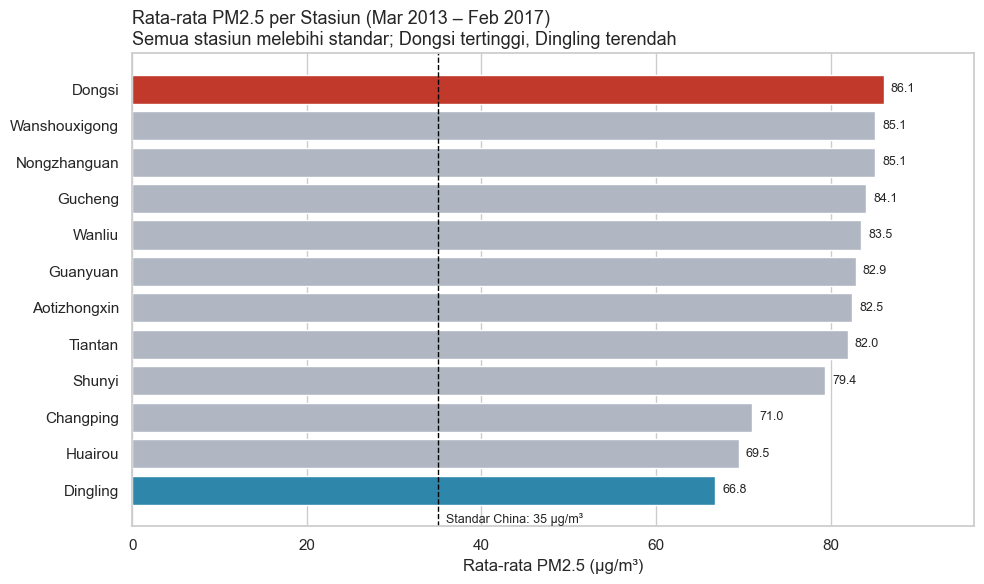

In [22]:
plot_df = station_pm25["mean"].sort_values()
colors = [COLOR_BASE] * len(plot_df)
colors[0] = COLOR_LOW
colors[-1] = COLOR_HIGHLIGHT

fig, ax = plt.subplots(figsize=(10, 6))
ax.barh(plot_df.index, plot_df.values, color=colors)
ax.axvline(STANDARD_PM25, color="black", linestyle="--", linewidth=1)
ax.text(STANDARD_PM25 + 1, -0.9, f"Standar China: {STANDARD_PM25} µg/m³", fontsize=9)
for i, v in enumerate(plot_df.values):
    ax.text(v + 0.8, i, f"{v:.1f}", va="center", fontsize=9)

ax.set_title("Rata-rata PM2.5 per Stasiun (Mar 2013 – Feb 2017)\nSemua stasiun melebihi standar; Dongsi tertinggi, Dingling terendah",
             fontsize=13, loc="left")
ax.set_xlabel("Rata-rata PM2.5 (µg/m³)")
ax.set_ylabel(None)
ax.set_xlim(0, plot_df.max() * 1.12)
ax.grid(axis="y", visible=False)
plt.tight_layout()
plt.show()

**Insight:**
- **Dongsi** memiliki rata-rata tertinggi (**86,1 µg/m³ ≈ 2,5× standar**), diikuti Nongzhanguan dan Wanshouxigong (85,1). Ketiganya berada di pusat kota dengan lalu lintas dan aktivitas padat.
- **Dingling** memiliki rata-rata terendah (**66,8 µg/m³ ≈ 1,9× standar**), bersama Huairou dan Changping yang terletak di pinggiran utara dekat area pegunungan.
- Bahkan stasiun terbersih pun masih hampir dua kali lipat standar, sehingga masalah polusi bersifat menyeluruh, bukan hanya lokal.

### Pertanyaan 2: Pada bulan dan jam berapa PM2.5 mencapai puncak dan titik terendahnya?

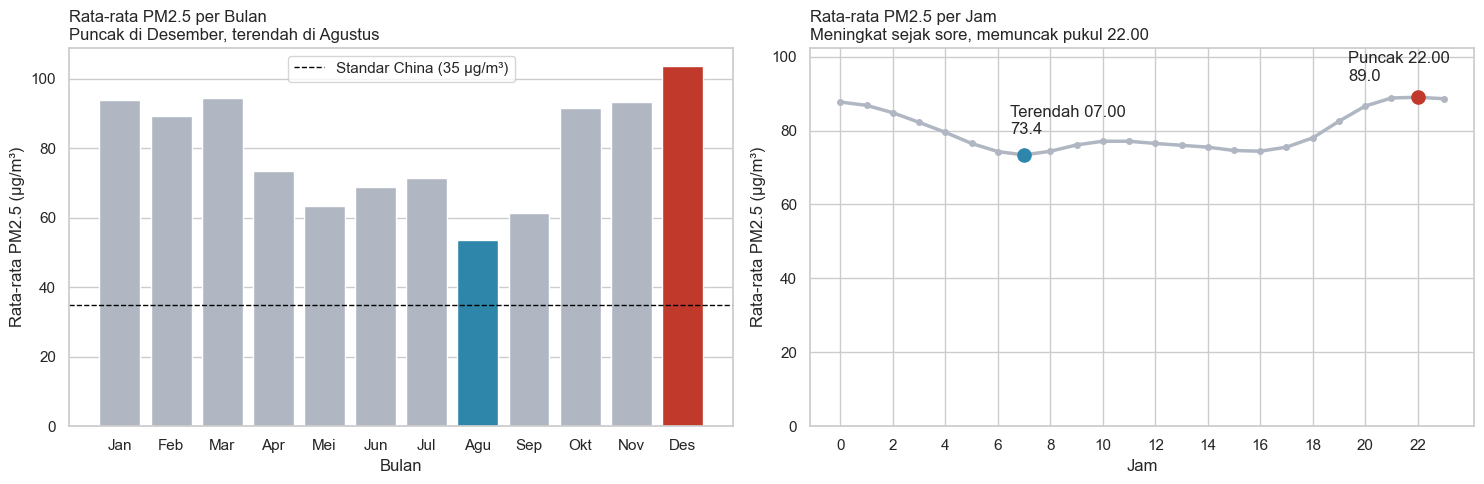

In [23]:
month_names = ["Jan", "Feb", "Mar", "Apr", "Mei", "Jun", "Jul", "Agu", "Sep", "Okt", "Nov", "Des"]
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# Pola bulanan
m_colors = [COLOR_BASE] * 12
m_colors[monthly_pm25.idxmax() - 1] = COLOR_HIGHLIGHT
m_colors[monthly_pm25.idxmin() - 1] = COLOR_LOW
axes[0].bar(month_names, monthly_pm25.values, color=m_colors)
axes[0].axhline(STANDARD_PM25, color="black", linestyle="--", linewidth=1, label="Standar China (35 µg/m³)")
axes[0].set_title("Rata-rata PM2.5 per Bulan\nPuncak di Desember, terendah di Agustus", loc="left")
axes[0].set_xlabel("Bulan")
axes[0].set_ylabel("Rata-rata PM2.5 (µg/m³)")
axes[0].legend(loc="upper center")
axes[0].grid(axis="x", visible=False)

# Pola per jam
axes[1].plot(hourly_pm25.index, hourly_pm25.values, color=COLOR_BASE, linewidth=2.5, marker="o", markersize=4)
axes[1].scatter(hourly_pm25.idxmax(), hourly_pm25.max(), color=COLOR_HIGHLIGHT, s=90, zorder=3)
axes[1].scatter(hourly_pm25.idxmin(), hourly_pm25.min(), color=COLOR_LOW, s=90, zorder=3)
axes[1].annotate(f"Puncak {hourly_pm25.idxmax():02d}.00\n{hourly_pm25.max():.1f}",
                 (hourly_pm25.idxmax(), hourly_pm25.max()), xytext=(-50, 12), textcoords="offset points")
axes[1].annotate(f"Terendah {hourly_pm25.idxmin():02d}.00\n{hourly_pm25.min():.1f}",
                 (hourly_pm25.idxmin(), hourly_pm25.min()), xytext=(-10, 15), textcoords="offset points")
axes[1].set_ylim(0, hourly_pm25.max() * 1.15)
axes[1].set_xticks(range(0, 24, 2))
axes[1].set_title("Rata-rata PM2.5 per Jam\nMeningkat sejak sore, memuncak pukul 22.00", loc="left")
axes[1].set_xlabel("Jam")
axes[1].set_ylabel("Rata-rata PM2.5 (µg/m³)")

plt.tight_layout()
plt.show()

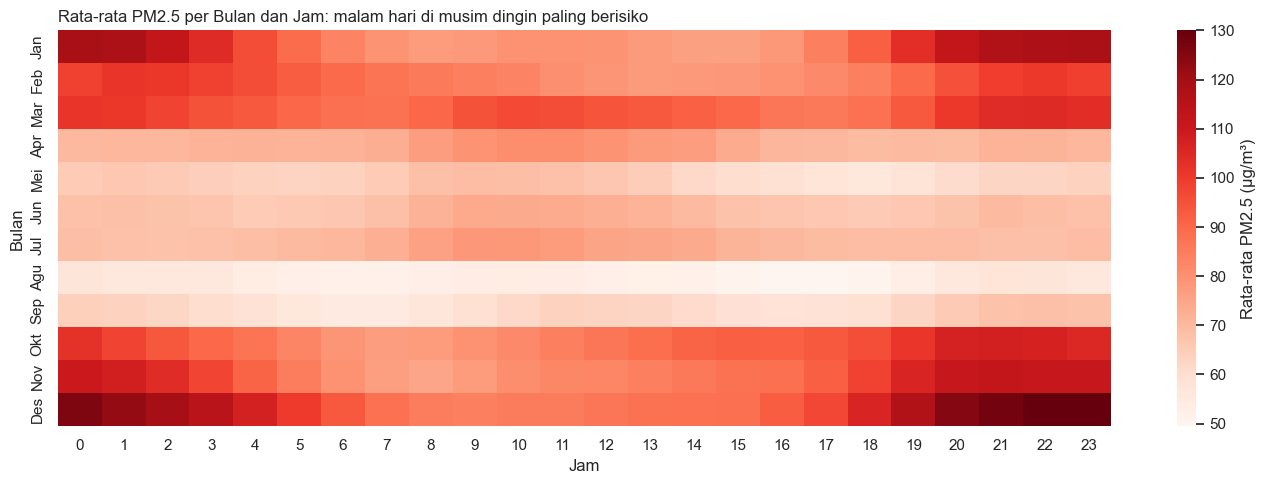

In [24]:
# Heatmap kombinasi bulan x jam untuk melihat interaksi keduanya
heat = clean_df.pivot_table(index="month", columns="hour", values="PM2.5", aggfunc="mean")
heat.index = month_names

fig, ax = plt.subplots(figsize=(14, 5))
sns.heatmap(heat, cmap="Reds", cbar_kws={"label": "Rata-rata PM2.5 (µg/m³)"}, ax=ax)
ax.set_title("Rata-rata PM2.5 per Bulan dan Jam: malam hari di musim dingin paling berisiko", loc="left")
ax.set_xlabel("Jam")
ax.set_ylabel("Bulan")
plt.tight_layout()
plt.show()

**Insight:**
- **Bulanan:** puncak terjadi pada **Desember (103,7 µg/m³)**, terendah pada **Agustus (53,5 µg/m³)**, dengan selisih **50,2 µg/m³** (hampir 2 kali lipat). Periode Oktober–Maret konsisten tinggi karena pemanasan ruangan berbahan bakar batu bara dan kondisi atmosfer yang stabil (inversi suhu).
- **Per jam:** konsentrasi terendah pada **07.00 (73,4 µg/m³)**, lalu naik sejak sore dan memuncak pada **22.00 (89,0 µg/m³)**, dengan selisih **15,6 µg/m³**.
- Heatmap menunjukkan kombinasi paling berbahaya adalah **malam hari pada bulan Desember–Februari**.

### Pertanyaan 3: Berapa persen perubahan PM2.5 tahunan dari 2013/14 ke 2016/17, dan apakah terjadi di semua stasiun?

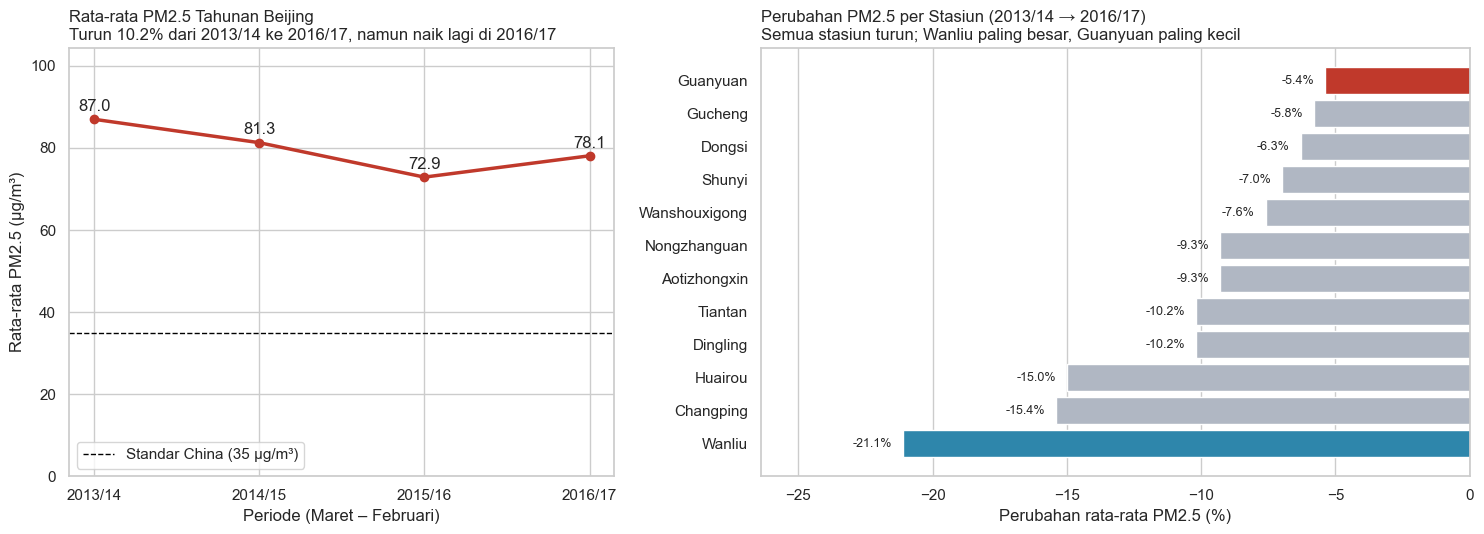

In [25]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5.5), gridspec_kw={"width_ratios": [1, 1.3]})

# Tren keseluruhan
axes[0].plot(periode_all.index, periode_all.values, color=COLOR_HIGHLIGHT, marker="o", linewidth=2.5)
for x, y in zip(periode_all.index, periode_all.values):
    axes[0].text(x, y + 2, f"{y:.1f}", ha="center")
axes[0].axhline(STANDARD_PM25, color="black", linestyle="--", linewidth=1, label="Standar China (35 µg/m³)")
axes[0].set_ylim(0, periode_all.max() * 1.2)
axes[0].set_title(f"Rata-rata PM2.5 Tahunan Beijing\nTurun {abs(change):.1f}% dari 2013/14 ke 2016/17, namun naik lagi di 2016/17",
                  loc="left")
axes[0].set_xlabel("Periode (Maret – Februari)")
axes[0].set_ylabel("Rata-rata PM2.5 (µg/m³)")
axes[0].legend(loc="lower left")

# Perubahan per stasiun
chg = periode_station["perubahan_%"].sort_values()
c_colors = [COLOR_LOW if v == chg.min() else (COLOR_HIGHLIGHT if v == chg.max() else COLOR_BASE) for v in chg]
axes[1].barh(chg.index, chg.values, color=c_colors)
for i, v in enumerate(chg.values):
    axes[1].text(v - 0.4, i, f"{v:.1f}%", va="center", ha="right", fontsize=9)
axes[1].axvline(0, color="black", linewidth=0.8)
axes[1].set_xlim(chg.min() * 1.25, 0)
axes[1].set_title("Perubahan PM2.5 per Stasiun (2013/14 → 2016/17)\nSemua stasiun turun; Wanliu paling besar, Guanyuan paling kecil",
                  loc="left")
axes[1].set_xlabel("Perubahan rata-rata PM2.5 (%)")
axes[1].grid(axis="y", visible=False)

plt.tight_layout()
plt.show()

**Insight:**
- Rata-rata PM2.5 Beijing turun dari **87,0 µg/m³ (2013/14)** menjadi **78,1 µg/m³ (2016/17)**, yaitu **turun 10,2%**.
- Penurunan **tidak konsisten setiap tahun**: titik terendah di 2015/16 (72,9), lalu naik kembali di 2016/17. Artinya perbaikan belum stabil.
- **Seluruh 12 stasiun mengalami penurunan**, tetapi besarnya bervariasi: **Wanliu −21,1%** (terbesar), Changping −15,4%, dan Huairou −15,0%, sedangkan stasiun pusat kota seperti **Guanyuan (−5,4%)**, Gucheng (−5,8%), dan Dongsi (−6,3%) membaik paling lambat.

## Analisis Lanjutan

### 1. Clustering dengan teknik Binning: kategori kualitas udara harian

**Tujuan:** mengubah nilai PM2.5 yang kontinu menjadi kategori yang mudah dipahami masyarakat, sehingga dapat diketahui
**berapa persen hari** yang tergolong sehat atau tercemar. Pengelompokan dilakukan **tanpa machine learning**, menggunakan
`pd.cut()` dengan batas rata-rata PM2.5 24 jam pada standar indeks kualitas udara China (HJ 633-2012):

| Rata-rata PM2.5 harian (µg/m³) | Kategori |
|---|---|
| 0 – 35 | Baik |
| 35 – 75 | Sedang |
| 75 – 115 | Tercemar Ringan |
| 115 – 150 | Tercemar Sedang |
| 150 – 250 | Tercemar Berat |
| > 250 | Sangat Berbahaya |

In [26]:
daily_df = (
    clean_df.groupby(["station", clean_df["datetime"].dt.date])["PM2.5"]
    .mean()
    .reset_index()
    .rename(columns={"datetime": "date"})
)

aqi_bins = [0, 35, 75, 115, 150, 250, np.inf]
aqi_labels = ["Baik", "Sedang", "Tercemar Ringan", "Tercemar Sedang", "Tercemar Berat", "Sangat Berbahaya"]
daily_df["kategori"] = pd.cut(daily_df["PM2.5"], bins=aqi_bins, labels=aqi_labels, right=True)

category_pct = daily_df["kategori"].value_counts(normalize=True).reindex(aqi_labels).mul(100).round(1)
category_pct

kategori
Baik                29.5
Sedang              30.1
Tercemar Ringan     18.2
Tercemar Sedang      9.5
Tercemar Berat       9.2
Sangat Berbahaya     3.4
Name: proportion, dtype: float64

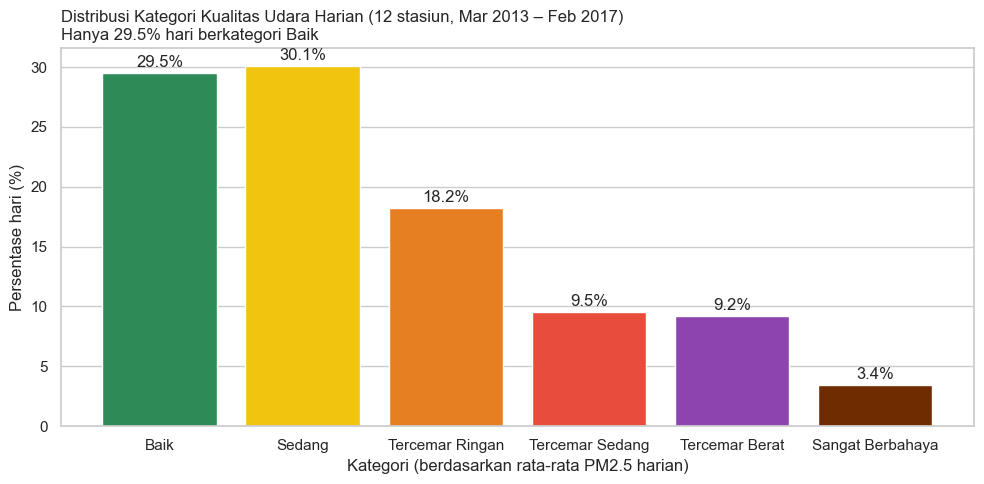

In [27]:
aqi_colors = ["#2E8B57", "#F1C40F", "#E67E22", "#E74C3C", "#8E44AD", "#6E2C00"]

fig, ax = plt.subplots(figsize=(10, 5))
bars = ax.bar(category_pct.index, category_pct.values, color=aqi_colors)
for bar, v in zip(bars, category_pct.values):
    ax.text(bar.get_x() + bar.get_width() / 2, v + 0.5, f"{v:.1f}%", ha="center")
ax.set_title("Distribusi Kategori Kualitas Udara Harian (12 stasiun, Mar 2013 – Feb 2017)\n"
             f"Hanya {category_pct['Baik']:.1f}% hari berkategori Baik", loc="left")
ax.set_xlabel("Kategori (berdasarkan rata-rata PM2.5 harian)")
ax.set_ylabel("Persentase hari (%)")
ax.grid(axis="x", visible=False)
plt.tight_layout()
plt.show()

In [28]:
# Proporsi hari tercemar (>= Tercemar Ringan, yaitu > 75 µg/m³) per stasiun
daily_df["tercemar"] = daily_df["PM2.5"] > 75
daily_df.groupby("station")["tercemar"].mean().mul(100).round(1).sort_values(ascending=False)

station
Dongsi           43.5
Gucheng          43.1
Nongzhanguan     42.8
Wanliu           42.8
Wanshouxigong    42.8
Guanyuan         42.2
Aotizhongxin     42.0
Tiantan          41.3
Shunyi           40.8
Changping        35.9
Huairou          34.8
Dingling         32.2
Name: tercemar, dtype: float64

**Insight:**
- Hanya sekitar **29,5%** hari yang berkategori **Baik**. Sekitar **40%** hari tergolong tercemar (rata-rata harian > 75 µg/m³), dan **±12,6%** hari masuk kategori **Tercemar Berat** atau **Sangat Berbahaya**.
- Stasiun pusat kota memiliki proporsi hari tercemar paling tinggi, sejalan dengan temuan Pertanyaan 1.

### 2. Geospatial Analysis: peta rata-rata PM2.5 per stasiun

**Tujuan:** melihat pola spasial polusi, yaitu apakah konsentrasi PM2.5 berkaitan dengan letak stasiun (pusat kota vs pinggiran).
Dataset tidak menyertakan koordinat, sehingga digunakan **koordinat perkiraan** lokasi tiap stasiun pemantauan di Beijing.
Peta dibuat dengan `folium`: ukuran dan warna lingkaran menunjukkan besarnya rata-rata PM2.5.

In [29]:
station_coords = {
    "Aotizhongxin": (39.982, 116.397), "Changping": (40.217, 116.230), "Dingling": (40.292, 116.220),
    "Dongsi": (39.929, 116.417), "Guanyuan": (39.929, 116.339), "Gucheng": (39.914, 116.184),
    "Huairou": (40.328, 116.628), "Nongzhanguan": (39.937, 116.461), "Shunyi": (40.127, 116.655),
    "Tiantan": (39.886, 116.407), "Wanliu": (39.987, 116.287), "Wanshouxigong": (39.878, 116.352),
}
geo_df = station_pm25[["mean"]].reset_index()
geo_df["lat"] = geo_df["station"].map(lambda s: station_coords[s][0])
geo_df["lon"] = geo_df["station"].map(lambda s: station_coords[s][1])
geo_df

,station,mean,lat,lon
0,Dongsi,86.1,39.929,116.417
1,Nongzhanguan,85.1,39.937,116.461
2,Wanshouxigong,85.1,39.878,116.352
3,Gucheng,84.1,39.914,116.184
4,Wanliu,83.5,39.987,116.287
5,Guanyuan,82.9,39.929,116.339
6,Aotizhongxin,82.5,39.982,116.397
7,Tiantan,82.0,39.886,116.407
8,Shunyi,79.4,40.127,116.655
9,Changping,71.0,40.217,116.230


In [30]:
vmin, vmax = geo_df["mean"].min(), geo_df["mean"].max()

def pm_color(value):
    # Gradasi kuning -> merah sesuai rata-rata PM2.5
    ratio = (value - vmin) / (vmax - vmin)
    if ratio > 0.75:
        return "#C0392B"
    if ratio > 0.5:
        return "#E67E22"
    if ratio > 0.25:
        return "#F5B041"
    return "#F7DC6F"

beijing_map = folium.Map(location=[40.05, 116.40], zoom_start=10, tiles="OpenStreetMap")
for _, row in geo_df.iterrows():
    folium.CircleMarker(
        location=[row["lat"], row["lon"]],
        radius=6 + (row["mean"] - vmin) / (vmax - vmin) * 14,
        color=pm_color(row["mean"]),
        fill=True,
        fill_opacity=0.8,
        tooltip=f"{row['station']}: {row['mean']:.1f} µg/m³",
    ).add_to(beijing_map)
beijing_map

**Insight:**
- Lingkaran besar berwarna merah terkumpul di **pusat kota** serta sisi **barat dan selatannya** (Dongsi, Nongzhanguan, Wanshouxigong, Gucheng), sedangkan lingkaran kecil berwarna kuning berada di **pinggiran utara** (Dingling, Changping, Huairou).
- Pola ini menunjukkan konsentrasi PM2.5 lebih tinggi di wilayah urban yang padat dan lebih rendah di pinggiran utara yang dekat dengan area pegunungan dan lebih jarang aktivitasnya.

### Menyimpan data bersih untuk dashboard
Data hasil cleaning disimpan ke `dashboard/main_data.csv` untuk digunakan oleh dashboard Streamlit.

In [31]:
dashboard_cols = ["datetime", "station", "PM2.5", "PM10", "SO2", "NO2", "CO", "O3", "TEMP", "WSPM", "wd"]
os.makedirs("dashboard", exist_ok=True)
clean_df[dashboard_cols].round(1).to_csv("dashboard/main_data.csv", index=False)
print("Tersimpan:", os.path.getsize("dashboard/main_data.csv") / 1e6, "MB")

Tersimpan: 31.071183 MB


## Conclusion & Recommendation

- **Conclusion pertanyaan 1:** Selama Mar 2013 – Feb 2017, **Dongsi** memiliki rata-rata PM2.5 tertinggi (**86,1 µg/m³, ≈ 2,5× standar China**) dan **Dingling** terendah (**66,8 µg/m³, ≈ 1,9× standar**). Seluruh 12 stasiun melampaui standar tahunan 35 µg/m³. Stasiun pusat kota konsisten lebih tercemar dibanding pinggiran utara.
- **Conclusion pertanyaan 2:** PM2.5 memuncak pada **Desember (103,7 µg/m³)** dan terendah pada **Agustus (53,5 µg/m³)**, dengan selisih 50,2 µg/m³. Dalam sehari, puncak terjadi pukul **22.00 (89,0 µg/m³)** dan terendah pukul **07.00 (73,4 µg/m³)**, dengan selisih 15,6 µg/m³. Waktu paling berisiko adalah malam hari di musim dingin.
- **Conclusion pertanyaan 3:** Rata-rata PM2.5 tahunan **turun 10,2%** (87,0 → 78,1 µg/m³) dari 2013/14 ke 2016/17 dan penurunan terjadi di **seluruh 12 stasiun**. Namun trennya tidak stabil (naik kembali di 2016/17), dan stasiun pusat kota (Guanyuan −5,4%, Gucheng −5,8%, Dongsi −6,3%) membaik jauh lebih lambat dibanding Wanliu (−21,1%).
- **Analisis lanjutan:** hanya ±29,5% hari berkategori Baik, dan PM2.5 meningkat ke arah pusat dan selatan kota.

**Rekomendasi Action Item:**
1. **Prioritaskan mitigasi di stasiun pusat kota** (Dongsi, Nongzhanguan, Wanshouxigong, Guanyuan, Gucheng): perketat pembatasan kendaraan, debu konstruksi, dan emisi lokal, karena wilayah ini paling tercemar sekaligus paling lambat membaik.
2. **Terapkan sistem peringatan dini musiman** pada Oktober–Maret, terutama malam hari (pukul 19.00–01.00): imbauan mengurangi aktivitas luar ruangan dan penggunaan masker bagi kelompok rentan, serta pengawasan ketat pemanas berbahan bakar batu bara.
3. **Percepat transisi energi pemanas ruangan** (batu bara → gas/listrik) untuk menekan puncak musim dingin, dan **evaluasi kebijakan setiap tahun** karena kenaikan di 2016/17 menunjukkan perbaikan belum permanen.
4. **Manfaatkan prakiraan cuaca**: kecepatan angin berkorelasi negatif dengan PM2.5, sehingga hari dengan angin lemah dapat dijadikan pemicu peringatan polusi lebih awal.